### Use this when data is missing at random

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
df=pd.read_csv("/home/ammar/AI Track/Machine-Learning/Handling Missing Values/Simple Imputer/Datasets/titanic_toy.csv")

In [15]:
df.head()

,Age,Fare,Family,Survived
0,22.0,7.2500,1,0
1,38.0,71.2833,1,1
2,26.0,7.9250,0,1
3,35.0,53.1000,1,1
4,35.0,8.0500,0,0


### Using Pandas

In [16]:
df['Age_median'] = df['Age'].fillna(df['Age'].median())

In [17]:
df['Fare_mean'] = df['Fare'].fillna(df['Fare'].mean())

In [18]:
df

,Age,Fare,Family,Survived,Age_median,Fare_mean
0,22.0,7.2500,1,0,22.0,7.250000
1,38.0,71.2833,1,1,38.0,71.283300
2,26.0,7.9250,0,1,26.0,7.925000
3,35.0,53.1000,1,1,35.0,53.100000
4,35.0,8.0500,0,0,35.0,8.050000
...,...,...,...,...,...,...
886,27.0,13.0000,0,0,27.0,13.000000
887,19.0,30.0000,0,1,19.0,30.000000
888,NaN,23.4500,3,0,28.0,23.450000
889,26.0,NaN,0,1,26.0,32.279338


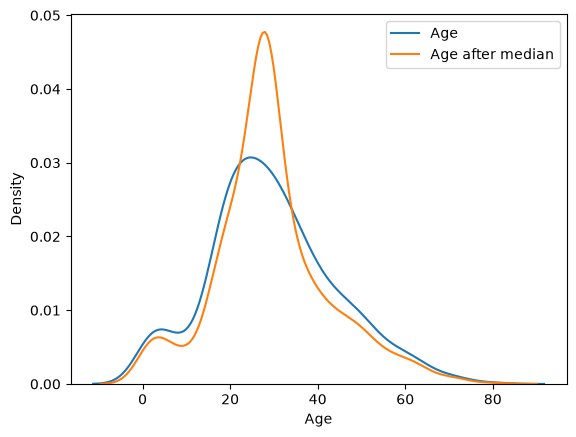

In [34]:
sns.kdeplot(df['Age'], label = 'Age')

sns.kdeplot(df['Age_median'],label = 'Age after median')
plt.legend()

# it has changed the distribution on age column

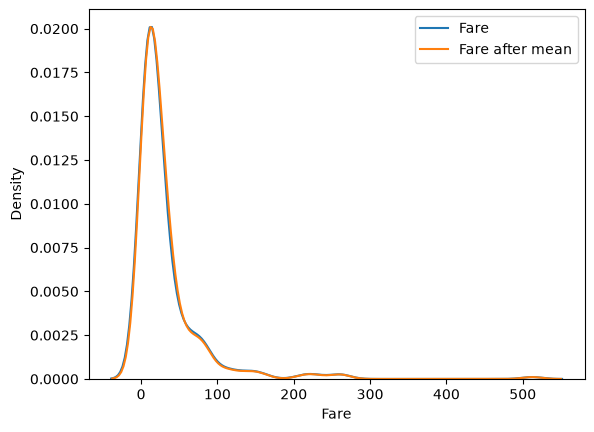

In [42]:
sns.kdeplot(df['Fare'], label = 'Fare')
sns.kdeplot(df['Fare_mean'], label = 'Fare after mean')
plt.legend()
#distribution is almost the same on fare column

In [58]:
df.var()
#variance of age has changed significantly

Age            211.019125
Fare          2530.673077
Family           2.603248
Survived         0.236772
Age_median     169.512498
Fare_mean     2402.717697
dtype: float64

In [56]:
df.cov()
# the covariance has changed

,Age,Fare,Family,Survived,Age_median,Fare_mean
Age,211.019125,78.071438,-6.507525,-0.551296,211.019125,73.727862
Fare,78.071438,2530.673077,17.460363,6.442361,65.546143,2530.673077
Family,-6.507525,17.460363,2.603248,0.013063,-5.159658,16.577535
Survived,-0.551296,6.442361,0.013063,0.236772,-0.411226,6.116624
Age_median,211.019125,65.546143,-5.159658,-0.411226,169.512498,62.232012
Fare_mean,73.727862,2530.673077,16.577535,6.116624,62.232012,2402.717697


In [57]:
df.corr()
#the correlation is same almost 

,Age,Fare,Family,Survived,Age_median,Fare_mean
Age,1.000000,0.099481,-0.301914,-0.077221,1.000000,0.097273
Fare,0.099481,1.000000,0.212626,0.263920,0.099626,1.000000
Family,-0.301914,0.212626,1.000000,0.016639,-0.245619,0.209609
Survived,-0.077221,0.263920,0.016639,1.000000,-0.064910,0.256445
Age_median,1.000000,0.099626,-0.245619,-0.064910,1.000000,0.097513
Fare_mean,0.097273,1.000000,0.209609,0.256445,0.097513,1.000000


### Using Scikit Learn

In [44]:
from sklearn.impute import SimpleImputer 
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

In [39]:
df_1 = pd.read_csv("/home/ammar/AI Track/Machine-Learning/Handling Missing Values/Simple Imputer/Datasets/titanic_toy.csv")

In [67]:
trf = ColumnTransformer ([
    ('impute age', SimpleImputer(), ['Age']),
    ('impute fare', SimpleImputer(strategy='median'), ['Fare'])
], remainder = 'passthrough' )

In [68]:
X_train, X_test, y_train, y_test = train_test_split(df.drop(columns='Survived'), df['Survived'], test_size = 0.2 )

In [69]:
x_tr = trf.fit_transform(X_train)
x_te = trf.fit(X_test)
#it has converted the series to np array

In [71]:
x_tr

array([[24.        , 79.2       ,  0.        , 24.        , 79.2       ],
       [48.        , 76.7292    ,  1.        , 48.        , 76.7292    ],
       [30.5       ,  7.75      ,  0.        , 30.5       ,  7.75      ],
       ...,
       [16.        ,  7.775     ,  0.        , 16.        ,  7.775     ],
       [29.65307018,  7.75      ,  0.        , 28.        ,  7.75      ],
       [24.        , 65.        ,  3.        , 24.        , 65.        ]],
      shape=(712, 5))

### Use this arbitrary value filler when data is not missing at random

In [ ]:
SimpleImputer(fill_value = 99,)
# 99 is arbitrary value
# this is mostly used for filling the categorical columns


### End of disribution Imputation 
for normally distributed data fill with Mean + 3 × standard deviation (or mean − 3 × SD) for roughly Gaussian variables

for skewed data fill with Q3 + 3 × IQR (or Q1 − 3 × IQR), which is more robust to skew and outliers